[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/blob/main/Tercera%20entrega/particion_temporal.ipynb)

# ¿Sobrevive el modelo al cambio de año? Partición temporal de RoBERTa-BNE

**Proyecto Integrador · Deep Learning · Fase 3**
Miguel Ángel Amézquita Briceño · Lis Alejandra Sánchez Moreno

## Qué pidió el profesor

En la retroalimentación de la Fase 2: *"una partición por tiempo, para saber si el modelo sobrevive al
cambio de año"*. Las noticias del corpus van de 2008 a 2026 y hasta ahora siempre se partieron al azar
(por grupos de variantes), de modo que el modelo veía noticias de todos los años en entrenamiento y en
prueba. Eso mide si reconoce noticias **parecidas a las que ya vio**, no si funciona con lo que viene
**después**.

## Lo que ya respondió la auditoría temporal (y lo que no)

`auditoria_interpretabilidad_modelo.ipynb`, sección 1, tomó el modelo de la Fase 2 (entrenado con la
partición aleatoria) y le modificó las entradas:

| Prueba de la auditoría | Resultado |
|---|---|
| §1.1 Noticias reales con fecha imposible (Petro gobernando en 2005 o 2018) | La probabilidad de "falsa" casi no cambia (de 0,045 a 0,050) y ninguna noticia cambia de clase: **el modelo ignora las fechas** |
| §1.2 Noticias reales de oct–nov 2026 con funcionarios nombrados después del corpus | 0 % marcadas como falsas, igual que el control (p = 0,57); cambiar el nombre del ministro por uno inventado no altera nada |
| §2 Noticias reales de otros medios reputables | Marcadas como falsas en el 29 % de los casos, frente al 0 % de El Espectador: **el modelo se apoya en la fuente** |

La auditoría respondió **"¿usa el modelo la información de tiempo?"**: no. Lo que no podía responder es
**"¿le cuesta rendimiento que el tiempo avance?"**, por cuatro razones:

1. El modelo auditado se entrenó con noticias de todos los años; nunca estuvo "en el pasado".
2. La §1.2 evaluó solo noticias **reales**: mide falsas alarmas, pero no si detecta **mentiras nuevas**.
3. Todas esas noticias eran de El Espectador, la fuente que el modelo ya asocia con "real".
4. Fueron 27 noticias a uno o dos meses del corte.

Este cuaderno completa esa pregunta: **entrena solo con el pasado y evalúa con el futuro, con noticias
reales y falsas, y compara contra una partición aleatoria del mismo tamaño.**

## Diseño

**Subconjunto 2018–2026.** Antes de 2018 el corpus no tiene **ninguna** noticia real (562 falsas, casi
todas sátira). Si se incluyeran, el entrenamiento temporal tendría todo eso y la prueba nada, y se
mediría el balance de clases en vez del tiempo. Se trabaja con 2.696 noticias de 2018 a 2026; la única
con fecha de 2028 (un error del corpus) se excluye.

Dos diseños temporales, cada uno con su **control aleatorio** de exactamente los mismos tamaños:

| Diseño | Entrenamiento | Validación | Prueba | Pregunta |
|---|---|---|---|---|
| **B · por año** (principal) | 2018–2024 (750) | 2025 (895) | 2026 (1.051) | ¿Sobrevive al cambio de año? (literal) |
| **A · por cuantiles** | el 70 % más antiguo (hasta mar-2026) | 15 % siguiente | 15 % más reciente (jun–sep 2026) | ¿Sobrevive a los meses siguientes, con mucho entrenamiento? |

Lo que se compara es **temporal frente a aleatoria con los mismos tamaños**: si la temporal cae, la
caída es el costo de no haber visto el futuro. Se corren los tres regímenes de la comparación anterior
(congelado, parcial y completo) con sus tasas ya elegidas, tres semillas cada uno, y TF-IDF + SVM.

**Advertencia de diseño, antes de ver resultados.** Partir por tiempo cambia además la proporción de
clases (2026 tiene 73 % de reales) y la mezcla de fuentes (la sátira desaparece después de 2024). Por
eso, además del F1 y el MCC, se reporta el recall de cada clase y el acierto **por fuente** en la prueba
(§16): así se distingue si la caída viene del tiempo o de que cambió quién publica.

**Requisitos:** Colab con GPU T4. Unos 50–70 minutos. Cada corrida se guarda en Drive al terminar y,
si Colab se desconecta, al volver a ejecutar se retoma donde quedó.

## §1 · Instalación e importaciones

In [1]:
import importlib.util, subprocess, sys
faltan = [p for p in ["transformers", "huggingface_hub", "openpyxl"] if importlib.util.find_spec(p) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)

In [2]:
import os, sys, json, time, math, random, hashlib, platform, re, unicodedata, shutil, glob, builtins
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef)

import transformers
from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
EN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python       :", platform.python_version())
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("scikit-learn :", sklearn.__version__)
print("Dispositivo  :", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
if DEVICE.type != "cuda":
    print("\n⚠️  Sin GPU: cambia el tipo de entorno a T4 antes de seguir.")

Python       : 3.13.16
torch        : 2.14.1+cu130
transformers : 5.22.1
scikit-learn : 1.6.1
Dispositivo  : Tesla T4


## §2 · Configuración (fijada antes de ver resultados)

Las tasas de aprendizaje son las que cada régimen eligió en validación en
`comparacion_regimenes_transferencia.ipynb`; aquí **no se vuelven a buscar**, para que la única diferencia
entre la partición temporal y la aleatoria sea cómo se reparten las noticias. El protocolo de entrenamiento
es el mismo (ganador de la búsqueda bayesiana de la Fase 2).

**Comparación principal:** régimen completo, diseño B (por año), temporal frente a aleatoria. El resto se
reporta como complemento.

In [3]:
CONFIG = {
    # ---------- DATOS ----------
    "url_corpus": ("https://raw.githubusercontent.com/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/"
                   "main/Segunda%20entrega/Dataset_politica_colombiana.xlsx"),
    "ruta_corpus": "dataset_politica_colombiana_3259.xlsx",
    "md5_corpus": "c432dac79cb39f80e503481411bd35db",
    "col_id": "id", "col_label": "label", "col_titulo": "title", "col_descripcion": "description",
    "col_fecha": "date", "formato_fecha": "%d/%m/%Y", "col_url": "url",
    "campos_texto": ["title", "description"],
    "fecha_min": "2018-01-01",     # antes de 2018 no hay noticias reales
    "fecha_max": "2026-12-31",     # excluye la fecha errónea de 2028

    # ---------- DISEÑOS DE PARTICIÓN ----------
    "disenos": {
        "B_por_anio": {"tipo": "anio", "train_hasta": 2024, "val": 2025, "test": 2026},
        "A_cuantiles": {"tipo": "cuantiles", "proporciones": [0.70, 0.15, 0.15]},
    },
    "seed_control_aleatorio": 16,

    # ---------- MODELO ----------
    "modelo_candidatos": ["PlanTL-GOB-ES/roberta-base-bne", "BSC-LT/roberta-base-bne",
                          "BSC-TeMU/roberta-base-bne", "IsGarrido/roberta-base-bne"],
    "modelo_respaldo": "bertin-project/bertin-roberta-base-spanish",
    "revisiones": {"IsGarrido/roberta-base-bne": "3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9"},
    "max_seq_length": 128,

    # ---------- PROTOCOLO (el mismo de la comparación de regímenes) ----------
    "batch_size": 8,
    "dropout": 0.07258496356733739,
    "weight_decay": 0.008547485565344062,
    "lr_reduce_factor": 0.3323028659735827,
    "lr_reduce_patience": 1,
    "min_lr": 1e-7,
    "early_stopping_patience": 3,
    "metrica_seleccion": "f1_macro",
    "usar_amp": True,

    # ---------- REGÍMENES: tasas elegidas en validación en la comparación de regímenes ----------
    "regimenes": {
        "congelado": {"capas_abiertas": 0,  "lr": 3e-4,   "epocas_techo": 40},
        "parcial":   {"capas_abiertas": 2,  "lr": 1.5e-4, "epocas_techo": 15},
        "completo":  {"capas_abiertas": 12, "lr": 2e-5,   "epocas_techo": 15},
    },
    "seeds": [42, 2026, 7],

    # ---------- LÍNEA BASE ----------
    "tfidf": {"ngram_range": (1, 2), "min_df": 2, "C": 1.0, "max_features": 300_000, "sublinear_tf": True},

    # ---------- SALIDA (tu carpeta de Drive) ----------
    "usar_drive": True,
    "dir_drive": "/content/drive/MyDrive/Ciencia de datos/Deep Learning/Proyecto 20% Deep Learning/Entrega 3/particion_temporal",
    "dir_local": "resultados_particion_temporal",

    # True: submuestra y 2 épocas, solo para comprobar el cableado (resultados no válidos)
    "modo_prueba": False,
}
print(json.dumps(CONFIG, indent=2, ensure_ascii=False, default=str))

{
  "url_corpus": "https://raw.githubusercontent.com/mamezquita/PROYECTO-DEEP-LEARNING-NOTICIAS/main/Segunda%20entrega/Dataset_politica_colombiana.xlsx",
  "ruta_corpus": "dataset_politica_colombiana_3259.xlsx",
  "md5_corpus": "c432dac79cb39f80e503481411bd35db",
  "col_id": "id",
  "col_label": "label",
  "col_titulo": "title",
  "col_descripcion": "description",
  "col_fecha": "date",
  "formato_fecha": "%d/%m/%Y",
  "col_url": "url",
  "campos_texto": [
    "title",
    "description"
  ],
  "fecha_min": "2018-01-01",
  "fecha_max": "2026-12-31",
  "disenos": {
    "B_por_anio": {
      "tipo": "anio",
      "train_hasta": 2024,
      "val": 2025,
      "test": 2026
    },
    "A_cuantiles": {
      "tipo": "cuantiles",
      "proporciones": [
        0.7,
        0.15,
        0.15
      ]
    }
  },
  "seed_control_aleatorio": 16,
  "modelo_candidatos": [
    "PlanTL-GOB-ES/roberta-base-bne",
    "BSC-LT/roberta-base-bne",
    "BSC-TeMU/roberta-base-bne",
    "IsGarrido/roberta-bas

## §3 · Carpeta de resultados y reanudación

In [4]:
DIR_BASE = CONFIG["dir_local"]
if CONFIG["usar_drive"] and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_BASE = CONFIG["dir_drive"]
if CONFIG["modo_prueba"]:
    DIR_BASE = DIR_BASE.rstrip("/") + "_PRUEBA"
DIR_RUNS = os.path.join(DIR_BASE, "runs")
os.makedirs(DIR_RUNS, exist_ok=True)
print(f"Resultados en: {DIR_BASE}")
print(f"Corridas ya terminadas: {len(os.listdir(DIR_RUNS))}")

Mounted at /content/drive
Resultados en: /content/drive/MyDrive/Ciencia de datos/Deep Learning/Proyecto 20% Deep Learning/Entrega 3/particion_temporal
Corridas ya terminadas: 0


In [5]:
def fijar_semillas(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semillas(16)

## §4 · Corpus: descarga, huella, limpieza y fechas

La limpieza es la misma de las fases anteriores. Las fechas se leen con su formato explícito
(día/mes/año): los cuadernos anteriores tenían `fecha_dayfirst = False`, que no afectaba a la partición
aleatoria pero sí importa aquí.

In [6]:
def md5_archivo(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


if not os.path.exists(CONFIG["ruta_corpus"]):
    try:
        import urllib.request
        urllib.request.urlretrieve(CONFIG["url_corpus"], CONFIG["ruta_corpus"])
    except Exception as e:
        print(f"No se pudo descargar ({type(e).__name__}).")
        if EN_COLAB:
            from google.colab import files
            print("Sube Dataset_politica_colombiana.xlsx (carpeta 'Segunda entrega' del repo):")
            subido = files.upload()
            os.rename(next(iter(subido)), CONFIG["ruta_corpus"])
        else:
            raise
assert md5_archivo(CONFIG["ruta_corpus"]) == CONFIG["md5_corpus"], "No es el corpus de la Fase 2."
print("✓ Mismo corpus de la Fase 2 (MD5 verificado).")


def cargar_y_limpiar(ruta, cfg):
    col_l, col_t, col_d = cfg["col_label"], cfg["col_titulo"], cfg["col_descripcion"]
    df = pd.read_excel(ruta).copy()
    for c in [col_t, col_d]:
        df[c] = df[c].fillna("").astype(str).str.strip()
    partes = [df[c] for c in cfg["campos_texto"]]
    df["texto"] = partes[0]
    for p in partes[1:]:
        df["texto"] = (df["texto"] + ". " + p).str.replace(r"\\.\\s*\\.", ".", regex=True)
    df["texto"] = df["texto"].str.strip()
    df = df[df["texto"].str.len() > 0]
    df[col_l] = pd.to_numeric(df[col_l], errors="coerce")
    df = df[df[col_l].isin([0, 1])]
    df[col_l] = df[col_l].astype(int)
    df = df.drop_duplicates(subset=[col_t, col_d, col_l]).reset_index(drop=True)
    df.insert(0, "row_id", np.arange(len(df)))
    return df


df = cargar_y_limpiar(CONFIG["ruta_corpus"], CONFIG)
COL_LABEL = CONFIG["col_label"]
df["fecha"] = pd.to_datetime(df[CONFIG["col_fecha"]].astype(str).str[:10], format=CONFIG["formato_fecha"],
                             errors="coerce")
df["fuente"] = df[CONFIG["col_url"]].astype(str).str.extract(r"https?://(?:www\.)?([^/]+)")[0].fillna("desconocida")
print(f"Corpus: {len(df):,} noticias · fechas no legibles: {df['fecha'].isna().sum()} · "
      f"rango {df['fecha'].min().date()} a {df['fecha'].max().date()}")

✓ Mismo corpus de la Fase 2 (MD5 verificado).
Corpus: 3,259 noticias · fechas no legibles: 0 · rango 2008-05-24 a 2028-10-07


## §5 · Agrupamiento anti-fuga

El mismo de las fases anteriores. En una partición temporal, dos variantes de una noticia pueden tener
fechas distintas; para que nunca queden en splits diferentes, **cada grupo toma la fecha de su noticia
más antigua** y se asigna completo a un solo split.

In [7]:
def normalizar_texto(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def asignar_grupos(df, cfg):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    tits = df[cfg["col_titulo"]].map(normalizar_texto).values
    descs = df[cfg["col_descripcion"]].map(normalizar_texto).values
    for i in range(len(df)):
        if tits[i]:
            union(("row", i), ("tit", tits[i]))
        if descs[i]:
            union(("row", i), ("des", descs[i]))
    raices = [find(("row", i)) for i in range(len(df))]
    codigo = {r: k for k, r in enumerate(dict.fromkeys(raices))}
    return np.array([codigo[r] for r in raices])


df["grupo"] = asignar_grupos(df, CONFIG)
df["fecha_grupo"] = df.groupby("grupo")["fecha"].transform("min")
print(f"Grupos: {df['grupo'].nunique():,}")

Grupos: 3,238


## §6 · Diagnóstico temporal del corpus

Antes de partir, cómo se reparten las clases y las fuentes en el tiempo (las fechas de la tabla de §7
son las de cada grupo, es decir, la de su noticia más antigua). Esta tabla justifica el recorte a
2018–2026 y anticipa la advertencia de diseño: el tiempo, el balance de clases y la mezcla de fuentes
cambian juntos.

label  falsas  reales
anio                 
2008        8       0
2009       17       0
2010       17       0
2011        2       0
2012        5       0
2013        6       0
2014      158       0
2015      152       0
2016      134       0
2017       63       0
2018      114     101
2019       74      13
2020       13      17
2021       27      16
2022       43     110
2023       33      13
2024      163      13
2025      314     581
2026      282     769
2028        1       0

Noticias por año y fuente (6 fuentes principales):
fuente  actualidadpanamericana.com  colombiacheck.com  elchiguirebipolar.net  elespectador.com  eltiempo.com  lasillavacia.com  otras
anio                                                                                                                                 
2008                             0                  0                      8                 0             0                 0      0
2009                             0                  0         

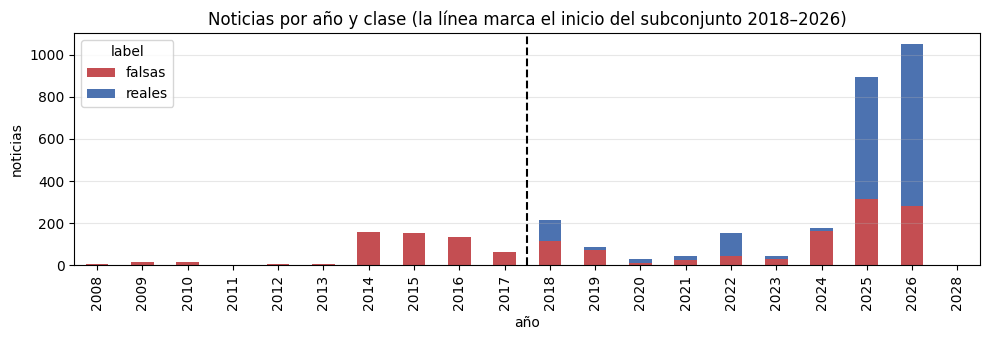


Subconjunto 2018–2026: 2,696 noticias · {0: 1063, 1: 1633} (0 = falsa) · excluidas: 563


In [8]:
df["anio"] = df["fecha"].dt.year
tabla_anios = pd.crosstab(df["anio"], df[COL_LABEL]).rename(columns={0: "falsas", 1: "reales"})
print(tabla_anios.to_string())

top = df["fuente"].value_counts().head(6).index
fuente_corta = df["fuente"].where(df["fuente"].isin(top), "otras")
print("\nNoticias por año y fuente (6 fuentes principales):")
print(pd.crosstab(df["anio"], fuente_corta).to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
tabla_anios.plot(kind="bar", stacked=True, ax=ax, color=["#C44E52", "#4C72B0"])
ax.axvline(list(tabla_anios.index).index(2018) - 0.5 if 2018 in tabla_anios.index else 0, color="k", ls="--")
ax.set_title("Noticias por año y clase (la línea marca el inicio del subconjunto 2018–2026)")
ax.set_xlabel("año"); ax.set_ylabel("noticias"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(DIR_BASE, "noticias_por_anio.png"), dpi=150); plt.show()

sub = df[(df["fecha_grupo"] >= CONFIG["fecha_min"]) & (df["fecha_grupo"] <= CONFIG["fecha_max"])].copy()
excluidas = len(df) - len(sub)
print(f"\nSubconjunto 2018–2026: {len(sub):,} noticias · {sub[COL_LABEL].value_counts().sort_index().to_dict()} "
      f"(0 = falsa) · excluidas: {excluidas}")

## §7 · Construcción de las particiones

- **Temporal B (por año):** según el año de la fecha del grupo: ≤ 2024 entrenamiento, 2025 validación,
  2026 prueba.
- **Temporal A (cuantiles):** se ordenan los grupos por fecha y se cortan en 70/15/15 de las noticias.
- **Control aleatorio:** para cada diseño, una partición aleatoria por grupos con **los mismos tamaños**
  de entrenamiento, validación y prueba, estratificada por clase. Se implementa con NumPy (no con
  `StratifiedGroupKFold`) para que no cambie con la versión de scikit-learn; además se guarda en CSV.

Todas las particiones se verifican: sin grupos repartidos entre splits y con tamaños idénticos entre la
temporal y su control.

In [9]:
def particion_temporal(sub, d):
    s = pd.Series(index=sub.index, dtype=object)
    if d["tipo"] == "anio":
        anio = sub["fecha_grupo"].dt.year
        s[anio <= d["train_hasta"]] = "train"
        s[anio == d["val"]] = "val"
        s[anio == d["test"]] = "test"
    else:
        orden = sub.sort_values(["fecha_grupo", "grupo", "row_id"])
        tam_grupo = orden.groupby("grupo", sort=False).size()
        acumulado = tam_grupo.cumsum() / tam_grupo.sum()
        p_tr, p_va, _ = d["proporciones"]
        etiqueta = np.where(acumulado <= p_tr, "train", np.where(acumulado <= p_tr + p_va, "val", "test"))
        mapa = dict(zip(tam_grupo.index, etiqueta))
        s[:] = sub["grupo"].map(mapa).values
    return s


def particion_aleatoria(sub, tamanos, seed):
    """Aleatoria por grupos, estratificada por clase, con los tamaños dados. Independiente de scikit-learn."""
    rng = np.random.default_rng(seed)
    g = sub.groupby("grupo").agg(n=("row_id", "size"), y=(COL_LABEL, lambda v: int(round(v.mean()))))
    total = len(sub)
    asignacion = {}
    for clase in (0, 1):
        grupos = g[g["y"] == clase]
        orden = rng.permutation(grupos.index.values)
        n_clase = grupos["n"].sum()
        metas = {k: tamanos[k] * n_clase / total for k in ["train", "val", "test"]}
        llenado = {"train": 0, "val": 0, "test": 0}
        for gid in orden:
            # el split con más déficit relativo recibe el grupo
            k = max(metas, key=lambda k: (metas[k] - llenado[k]) / max(metas[k], 1e-9))
            asignacion[gid] = k
            llenado[k] += grupos.loc[gid, "n"]
    return sub["grupo"].map(asignacion)


PARTICIONES = {}
for nombre, d in CONFIG["disenos"].items():
    temporal = particion_temporal(sub, d)
    tamanos = temporal.value_counts().to_dict()
    aleatoria = particion_aleatoria(sub, tamanos, CONFIG["seed_control_aleatorio"])
    PARTICIONES[f"{nombre}__temporal"] = temporal
    PARTICIONES[f"{nombre}__aleatoria"] = aleatoria

filas = []
for nombre, s in PARTICIONES.items():
    fuga = sub.assign(split=s.values).groupby("grupo")["split"].nunique().gt(1).sum()
    assert fuga == 0, f"{nombre}: {fuga} grupos repartidos"
    for split in ["train", "val", "test"]:
        m = s.values == split
        filas.append({"particion": nombre, "split": split, "n": int(m.sum()),
                      "% reales": round(100 * sub.loc[m, COL_LABEL].mean(), 1),
                      "desde": sub.loc[m, "fecha_grupo"].min().date(), "hasta": sub.loc[m, "fecha_grupo"].max().date(),
                      "% El Espectador": round(100 * (sub.loc[m, "fuente"] == "elespectador.com").mean(), 1)})
resumen_part = pd.DataFrame(filas)
print(resumen_part.to_string(index=False))

for nombre in CONFIG["disenos"]:
    t = {str(k): int(v) for k, v in PARTICIONES[f"{nombre}__temporal"].value_counts().items()}
    a = {str(k): int(v) for k, v in PARTICIONES[f"{nombre}__aleatoria"].value_counts().items()}
    print(f"\n{nombre}: tamaños temporal {t} · aleatoria {a}")
    assert abs(t["train"] - a["train"]) <= 3 and abs(t["test"] - a["test"]) <= 3, "Tamaños distintos"
print("\n✓ Sin fuga entre splits y tamaños emparejados.")

tabla_part = sub[["row_id", CONFIG["col_id"], "fecha", "fuente", "grupo", COL_LABEL]].copy()
for nombre, s in PARTICIONES.items():
    tabla_part[nombre] = s.values
tabla_part.to_csv(os.path.join(DIR_BASE, "particiones_temporales.csv"), index=False)
resumen_part.to_csv(os.path.join(DIR_BASE, "resumen_particiones.csv"), index=False)

             particion split    n  % reales      desde      hasta  % El Espectador
  B_por_anio__temporal train  750      37.7 2018-01-09 2024-12-27             14.0
  B_por_anio__temporal   val  905      65.3 2025-01-02 2025-12-31             64.0
  B_por_anio__temporal  test 1041      72.9 2026-01-01 2026-09-19             70.7
 B_por_anio__aleatoria train  750      60.5 2018-01-16 2026-09-19             51.9
 B_por_anio__aleatoria   val  905      60.6 2018-01-15 2026-09-19             53.8
 B_por_anio__aleatoria  test 1041      60.6 2018-01-09 2026-09-19             52.3
 A_cuantiles__temporal train 1887      55.2 2018-01-09 2026-03-18             44.7
 A_cuantiles__temporal   val  404      66.1 2026-03-18 2026-06-24             64.9
 A_cuantiles__temporal  test  405      80.2 2026-06-24 2026-09-19             77.5
A_cuantiles__aleatoria train 1885      60.6 2018-01-09 2026-09-19             52.9
A_cuantiles__aleatoria   val  405      60.5 2018-01-22 2026-09-17             53.1
A_cu

In [10]:
if CONFIG["modo_prueba"]:
    rng = np.random.default_rng(0)
    for nombre, s in PARTICIONES.items():
        nueva = pd.Series(None, index=s.index, dtype=object)
        for split, n in {"train": 48, "val": 24, "test": 24}.items():
            idx = s.index[s.values == split]
            nueva[rng.choice(idx, size=min(n, len(idx)), replace=False)] = split
        PARTICIONES[nombre] = nueva
    for r in CONFIG["regimenes"].values():
        r["epocas_techo"] = 2
    CONFIG["seeds"] = CONFIG["seeds"][:1]
    print("MODO PRUEBA: submuestra pequeña por split.")

## §8 · Línea base TF-IDF + SVM en cada partición

La misma configuración de la Fase 2, reentrenada en cada partición (vocabulario ajustado solo con su
entrenamiento).

In [11]:
def calcular_metricas(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "recall_falsa": float(recall_score(y_true, y_pred, pos_label=0, zero_division=0)),
        "recall_real": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "precision_falsa": float(precision_score(y_true, y_pred, pos_label=0, zero_division=0)),
    }


def indices(nombre, split):
    s = PARTICIONES[nombre]
    return np.where(s.values == split)[0]          # posiciones dentro de `sub`


sub = sub.reset_index(drop=True)
for k in PARTICIONES:
    PARTICIONES[k] = PARTICIONES[k].reset_index(drop=True)

t = CONFIG["tfidf"]
TFIDF = {}
for nombre in PARTICIONES:
    tr, te = indices(nombre, "train"), indices(nombre, "test")
    vec = TfidfVectorizer(ngram_range=t["ngram_range"], min_df=t["min_df"], max_features=t["max_features"],
                          sublinear_tf=t["sublinear_tf"], strip_accents="unicode", lowercase=True)
    clf = LinearSVC(C=t["C"], max_iter=5000, random_state=16).fit(
        vec.fit_transform(sub.loc[tr, "texto"]), sub.loc[tr, COL_LABEL])
    pred = clf.predict(vec.transform(sub.loc[te, "texto"]))
    TFIDF[nombre] = {"pred": pred, "metricas": calcular_metricas(sub.loc[te, COL_LABEL].values, pred)}
    m = TFIDF[nombre]["metricas"]
    print(f"{nombre:<26} F1 {m['f1_macro']:.4f} · MCC {m['mcc']:.4f} · "
          f"recall falsa {m['recall_falsa']:.3f} · recall real {m['recall_real']:.3f}")

B_por_anio__temporal       F1 0.6036 · MCC 0.3811 · recall falsa 0.926 · recall real 0.490
B_por_anio__aleatoria      F1 0.8977 · MCC 0.7978 · recall falsa 0.834 · recall real 0.949
A_cuantiles__temporal      F1 0.8902 · MCC 0.7849 · recall falsa 0.900 · recall real 0.932
A_cuantiles__aleatoria     F1 0.9165 · MCC 0.8343 · recall falsa 0.869 · recall real 0.955


## §9 · Modelo preentrenado y tokenización

El mismo espejo fijado al mismo commit que en las fases anteriores. Se tokenizan todas las noticias del
subconjunto una vez; cada partición toma sus filas por índice.

In [12]:
from huggingface_hub import list_repo_files, model_info, login

if EN_COLAB:
    try:
        from google.colab import userdata
        login(token=userdata.get("HF_TOKEN"), add_to_git_credential=False)
    except Exception:
        print("Sin secreto HF_TOKEN: se usará el espejo público.")

PESOS = ("model.safetensors", "pytorch_model.bin")


def resolver_modelo(cfg):
    for repo in list(cfg["modelo_candidatos"]) + [cfg["modelo_respaldo"]]:
        if os.path.isdir(repo):
            if os.path.exists(os.path.join(repo, "config.json")):
                return repo, None
            continue
        try:
            rev = cfg["revisiones"].get(repo)
            archivos = set(list_repo_files(repo, revision=rev))
            if "config.json" in archivos and any(p in archivos for p in PESOS):
                return repo, rev or model_info(repo).sha
        except Exception as e:
            print(f"  ✗ {type(e).__name__:<17} {repo}")
    raise RuntimeError("Ningún candidato tiene pesos descargables.")


MODELO, REVISION = resolver_modelo(CONFIG)
tokenizer = AutoTokenizer.from_pretrained(MODELO, revision=REVISION)
enc = tokenizer(list(sub["texto"]), truncation=True, padding="max_length",
                max_length=CONFIG["max_seq_length"], return_tensors="pt")
TOK = (enc["input_ids"], enc["attention_mask"], torch.tensor(sub[COL_LABEL].values, dtype=torch.long))
print(f"Modelo: {MODELO} @ {REVISION} · tokens: {tuple(TOK[0].shape)}")

Sin secreto HF_TOKEN: se usará el espejo público.
  ✗ RepositoryNotFoundError BSC-LT/roberta-base-bne
  ✗ RepositoryNotFoundError BSC-TeMU/roberta-base-bne


Modelo: IsGarrido/roberta-base-bne @ 3d54a71ddc029cc1f8dd604e3b7bc0da0e2f7cd9 · tokens: (2696, 128)


## §10 · Regímenes y motor de entrenamiento

Idénticos a `comparacion_regimenes_transferencia.ipynb` (§11–§12): congelar todo, abrir la cabeza y las
últimas *k* capas; el régimen congelado entrena la cabeza sobre los vectores `[CLS]` calculados una vez,
lo que es equivalente y mucho más rápido. La única diferencia es que aquí cada corrida recibe los índices
de su partición.

In [13]:
def cargar_modelo(seed):
    fijar_semillas(seed)
    d = CONFIG["dropout"]
    config = AutoConfig.from_pretrained(
        MODELO, revision=REVISION, num_labels=2, hidden_dropout_prob=d, attention_probs_dropout_prob=d,
        classifier_dropout=d, id2label={0: "falsa", 1: "real"}, label2id={"falsa": 0, "real": 1})
    try:
        m = AutoModelForSequenceClassification.from_pretrained(MODELO, revision=REVISION, config=config,
                                                               dtype=torch.float32)
    except TypeError:
        m = AutoModelForSequenceClassification.from_pretrained(MODELO, revision=REVISION, config=config,
                                                               torch_dtype=torch.float32)
    return m.to(DEVICE)


def aplicar_regimen(modelo, capas_abiertas):
    base = modelo.base_model
    capas = list(base.encoder.layer)
    n = len(capas)
    k = min(capas_abiertas, n)
    for p in modelo.parameters():
        p.requires_grad = False
    for p in modelo.classifier.parameters():
        p.requires_grad = True
    for capa in capas[n - k:]:
        for p in capa.parameters():
            p.requires_grad = True
    congelados = capas[:n - k]
    if k == n:
        for p in base.embeddings.parameters():
            p.requires_grad = True
    else:
        congelados = [base.embeddings] + congelados
    return congelados


@torch.no_grad()
def extraer_cls(modelo, lote=64):
    modelo.eval()
    salida = []
    for i in range(0, len(TOK[0]), lote):
        h = modelo.base_model(input_ids=TOK[0][i:i+lote].to(DEVICE),
                              attention_mask=TOK[1][i:i+lote].to(DEVICE)).last_hidden_state
        salida.append(h[:, 0, :].float().cpu())
    return torch.cat(salida)


_m = cargar_modelo(16)
t0 = time.time()
CLS = extraer_cls(_m)
print(f"Vectores [CLS] de {len(CLS):,} noticias en {time.time()-t0:.0f} s")
_m.eval()
with torch.no_grad():
    directo = _m(input_ids=TOK[0][:16].to(DEVICE), attention_mask=TOK[1][:16].to(DEVICE)).logits.float().cpu()
    atajo = _m.classifier(CLS[:16].to(DEVICE).unsqueeze(1)).float().cpu()
assert (directo - atajo).abs().max().item() < 1e-3
print("✓ Atajo del régimen congelado equivalente al modelo completo.")
del _m
torch.cuda.empty_cache()

Vectores [CLS] de 2,696 noticias en 15 s
✓ Atajo del régimen congelado equivalente al modelo completo.


In [14]:
def adelante(modelo, lote, usa_cls):
    if usa_cls:
        return modelo.classifier(lote[0].to(DEVICE).unsqueeze(1))
    return modelo(input_ids=lote[0].to(DEVICE), attention_mask=lote[1].to(DEVICE)).logits


def dataset(idx, usa_cls):
    idx = torch.as_tensor(idx)
    if usa_cls:
        return TensorDataset(CLS[idx], TOK[2][idx])
    return TensorDataset(TOK[0][idx], TOK[1][idx], TOK[2][idx])


@torch.no_grad()
def predecir(modelo, cargador, usa_cls, amp):
    modelo.eval()
    probs, ys, perd = [], [], []
    for lote in cargador:
        y = lote[-1].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=amp):
            logits = adelante(modelo, lote, usa_cls)
        perd.append(torch.nn.functional.cross_entropy(logits.float(), y, reduction="sum").item())
        probs.append(torch.softmax(logits.float(), -1).cpu())
        ys.append(y.cpu())
    y = torch.cat(ys).numpy()
    return torch.cat(probs).numpy(), y, builtins.sum(perd) / len(y)


def entrenar_corrida(particion, regimen, seed, verbose=False, limite_pasos=None):
    r = CONFIG["regimenes"][regimen]
    usa_cls = r["capas_abiertas"] == 0
    amp = CONFIG["usar_amp"] and DEVICE.type == "cuda" and not usa_cls
    idx = {s: indices(particion, s) for s in ["train", "val", "test"]}
    modelo = cargar_modelo(seed)
    congelados = aplicar_regimen(modelo, r["capas_abiertas"])
    gen = torch.Generator().manual_seed(seed)
    dl_tr = DataLoader(dataset(idx["train"], usa_cls), batch_size=CONFIG["batch_size"], shuffle=True, generator=gen)
    dl_va = DataLoader(dataset(idx["val"], usa_cls), batch_size=64)
    dl_te = DataLoader(dataset(idx["test"], usa_cls), batch_size=64)

    parametros = [p for p in modelo.parameters() if p.requires_grad]
    optim = torch.optim.AdamW(parametros, lr=r["lr"], weight_decay=CONFIG["weight_decay"], eps=1e-7)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode="max", factor=CONFIG["lr_reduce_factor"], patience=CONFIG["lr_reduce_patience"],
        threshold=1e-4, threshold_mode="abs", min_lr=CONFIG["min_lr"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=amp)

    historial, mejor, mejor_epoca, sin_mejora, mejor_estado = [], -1.0, 0, 0, None
    t0, pasos = time.time(), 0
    for epoca in range(1, r["epocas_techo"] + 1):
        modelo.train()
        for mod in congelados:
            mod.eval()
        perd = []
        for lote in dl_tr:
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp):
                loss = torch.nn.functional.cross_entropy(adelante(modelo, lote, usa_cls).float(),
                                                         lote[-1].to(DEVICE))
            scaler.scale(loss).backward()
            scaler.step(optim)
            scaler.update()
            perd.append(loss.item())
            pasos += 1
            if limite_pasos and pasos >= limite_pasos:
                break
        p_va, y_va, loss_va = predecir(modelo, dl_va, usa_cls, amp)
        m_va = calcular_metricas(y_va, p_va.argmax(1))
        historial.append({"epoca": epoca, "train_loss": float(np.mean(perd)), "val_loss": loss_va,
                          "lr": optim.param_groups[0]["lr"], **{f"val_{k}": v for k, v in m_va.items()}})
        score = m_va[CONFIG["metrica_seleccion"]]
        if score > mejor:
            mejor, mejor_epoca, sin_mejora = score, epoca, 0
            mejor_estado = {n: p.detach().cpu().clone() for n, p in modelo.named_parameters() if p.requires_grad}
        else:
            sin_mejora += 1
        if verbose:
            print(f"    época {epoca:>2} · train {np.mean(perd):.4f} · val {loss_va:.4f} · F1 {m_va['f1_macro']:.4f}")
        sched.step(score)
        if (limite_pasos and pasos >= limite_pasos) or sin_mejora >= CONFIG["early_stopping_patience"]:
            break
    modelo.load_state_dict(mejor_estado, strict=False)
    p_va, y_va, _ = predecir(modelo, dl_va, usa_cls, amp)
    p_te, y_te, _ = predecir(modelo, dl_te, usa_cls, amp)
    res = {"particion": particion, "regimen": regimen, "lr": r["lr"], "seed": seed,
           "n_train": len(idx["train"]), "n_val": len(idx["val"]), "n_test": len(idx["test"]),
           "mejor_epoca": mejor_epoca, "epocas_corridas": len(historial),
           "minutos": (time.time() - t0) / 60, "segundos_por_paso": (time.time() - t0) / max(pasos, 1),
           "val": calcular_metricas(y_va, p_va.argmax(1)), "test": calcular_metricas(y_te, p_te.argmax(1)),
           "modelo": MODELO, "revision": REVISION, "fecha": datetime.now(timezone.utc).isoformat(timespec="seconds")}
    pred_te = pd.DataFrame({"row_id": sub.loc[idx["test"], "row_id"].values, "y_true": y_te,
                            "prob_real": p_te[:, 1], "y_pred": p_te.argmax(1)})
    del modelo
    torch.cuda.empty_cache()
    return res, pd.DataFrame(historial), pred_te


def correr(particion, regimen, seed):
    nombre = f"{particion}__{regimen}__seed{seed}"
    d = os.path.join(DIR_RUNS, nombre)
    if os.path.exists(os.path.join(d, "resultado.json")):
        return json.load(open(os.path.join(d, "resultado.json")))
    res, hist, pred = entrenar_corrida(particion, regimen, seed)
    os.makedirs(d + ".tmp", exist_ok=True)
    hist.to_csv(os.path.join(d + ".tmp", "historial.csv"), index=False)
    pred.to_csv(os.path.join(d + ".tmp", "pred_test.csv"), index=False)
    with open(os.path.join(d + ".tmp", "resultado.json"), "w") as f:
        json.dump(res, f, indent=2)
    if os.path.exists(d):
        shutil.rmtree(d)
    os.rename(d + ".tmp", d)
    print(f"  {nombre}: F1 val {res['val']['f1_macro']:.4f} · mejor época {res['mejor_epoca']} · "
          f"{res['minutos']:.1f} min")
    return res

print("Motor listo.")

Motor listo.


## §11 · Prueba de humo y estimación de tiempo

In [15]:
velocidad = {}
p0 = next(iter(PARTICIONES))
for regimen in CONFIG["regimenes"]:
    res, _, _ = entrenar_corrida(p0, regimen, CONFIG["seeds"][0], limite_pasos=15)
    velocidad[regimen] = res["segundos_por_paso"]
    print(f"✓ {regimen:<10} {res['segundos_por_paso']*1000:7.1f} ms por paso")

plan = [(p, r, s) for p in PARTICIONES for r in CONFIG["regimenes"] for s in CONFIG["seeds"]]
seg = builtins.sum(velocidad[r] * math.ceil(len(indices(p, "train")) / CONFIG["batch_size"]) * 7
                   for p, r, s in plan)
print(f"\n{len(plan)} corridas · estimación ≈ {seg/60:.0f} min de entrenamiento, más la evaluación por época.")

✓ congelado     23.0 ms por paso
✓ parcial      300.1 ms por paso
✓ completo     403.5 ms por paso

36 corridas · estimación ≈ 168 min de entrenamiento, más la evaluación por época.


## §12 · Ejecución

Primero el diseño B (por año), que es la comparación principal; después el A. Para cada partición se
corren los tres regímenes con las tres semillas.

In [16]:
t0 = time.time()
orden = sorted(plan, key=lambda x: (not x[0].startswith("B_"), x[0], x[1], x[2]))
for particion, regimen, seed in orden:
    correr(particion, regimen, seed)
print(f"\nListo en {(time.time() - t0)/60:.1f} min.")

  B_por_anio__aleatoria__completo__seed7: F1 val 0.9377 · mejor época 9 · 2.2 min
  B_por_anio__aleatoria__completo__seed42: F1 val 0.9258 · mejor época 3 · 1.1 min
  B_por_anio__aleatoria__completo__seed2026: F1 val 0.9323 · mejor época 6 · 1.7 min
  B_por_anio__aleatoria__congelado__seed7: F1 val 0.9232 · mejor época 9 · 0.0 min
  B_por_anio__aleatoria__congelado__seed42: F1 val 0.9184 · mejor época 5 · 0.0 min
  B_por_anio__aleatoria__congelado__seed2026: F1 val 0.9261 · mejor época 10 · 0.0 min
  B_por_anio__aleatoria__parcial__seed7: F1 val 0.9291 · mejor época 2 · 0.4 min
  B_por_anio__aleatoria__parcial__seed42: F1 val 0.9372 · mejor época 8 · 0.8 min
  B_por_anio__aleatoria__parcial__seed2026: F1 val 0.9305 · mejor época 6 · 0.7 min
  B_por_anio__temporal__completo__seed7: F1 val 0.8369 · mejor época 5 · 1.5 min
  B_por_anio__temporal__completo__seed42: F1 val 0.8263 · mejor época 3 · 1.1 min
  B_por_anio__temporal__completo__seed2026: F1 val 0.8413 · mejor época 3 · 1.1 min
  

## §13 · Resultados: temporal frente a aleatoria

Para cada diseño y régimen, media ± desviación de las tres semillas en prueba. La columna **caída** es
temporal − aleatoria con los mismos tamaños: negativa significa que entrenar solo con el pasado cuesta
rendimiento.

In [17]:
filas = []
for ruta in sorted(glob.glob(os.path.join(DIR_RUNS, "*", "resultado.json"))):
    r = json.load(open(ruta))
    disenio, tipo = r["particion"].split("__")
    fila = {"diseno": disenio, "tipo": tipo, "regimen": r["regimen"], "seed": r["seed"],
            "n_train": r["n_train"], "n_test": r["n_test"], "mejor_epoca": r["mejor_epoca"],
            "minutos": r["minutos"], "dir": os.path.dirname(ruta)}
    fila.update({f"val_{k}": v for k, v in r["val"].items()})
    fila.update({f"test_{k}": v for k, v in r["test"].items()})
    filas.append(fila)
for nombre, v in TFIDF.items():
    disenio, tipo = nombre.split("__")
    fila = {"diseno": disenio, "tipo": tipo, "regimen": "tfidf_svm", "seed": 0}
    fila.update({f"test_{k}": val for k, val in v["metricas"].items()})
    filas.append(fila)
corridas = pd.DataFrame(filas)
corridas.drop(columns="dir").to_csv(os.path.join(DIR_BASE, "corridas_temporal.csv"), index=False)

def ms(x):
    return f"{x.mean():.3f} ± {x.std():.3f}" if len(x) > 1 else f"{x.mean():.3f}"

tabla = []
for disenio in CONFIG["disenos"]:
    for regimen in list(CONFIG["regimenes"]) + ["tfidf_svm"]:
        c = corridas[(corridas["diseno"] == disenio) & (corridas["regimen"] == regimen)]
        if c.empty:
            continue
        t_, a_ = c[c["tipo"] == "temporal"], c[c["tipo"] == "aleatoria"]
        tabla.append({"diseño": disenio, "modelo": regimen,
                      "F1 aleatoria": ms(a_["test_f1_macro"]), "F1 temporal": ms(t_["test_f1_macro"]),
                      "caída F1": f"{t_['test_f1_macro'].mean() - a_['test_f1_macro'].mean():+.3f}",
                      "MCC aleatoria": ms(a_["test_mcc"]), "MCC temporal": ms(t_["test_mcc"]),
                      "recall falsa (aleat. → temp.)": f"{a_['test_recall_falsa'].mean():.3f} → {t_['test_recall_falsa'].mean():.3f}",
                      "recall real (aleat. → temp.)": f"{a_['test_recall_real'].mean():.3f} → {t_['test_recall_real'].mean():.3f}"})
tabla = pd.DataFrame(tabla)
tabla.to_csv(os.path.join(DIR_BASE, "tabla_temporal.csv"), index=False)
print(tabla.to_string(index=False))

     diseño    modelo  F1 aleatoria   F1 temporal caída F1 MCC aleatoria  MCC temporal recall falsa (aleat. → temp.) recall real (aleat. → temp.)
 B_por_anio congelado 0.921 ± 0.007 0.761 ± 0.024   -0.160 0.843 ± 0.014 0.563 ± 0.035                 0.896 → 0.875                0.944 → 0.750
 B_por_anio   parcial 0.934 ± 0.012 0.840 ± 0.043   -0.094 0.868 ± 0.025 0.695 ± 0.071                 0.925 → 0.862                0.945 → 0.866
 B_por_anio  completo 0.940 ± 0.007 0.833 ± 0.022   -0.107 0.881 ± 0.015 0.670 ± 0.045                 0.907 → 0.816                0.967 → 0.880
 B_por_anio tfidf_svm         0.898         0.604   -0.294         0.798         0.381                 0.834 → 0.926                0.949 → 0.490
A_cuantiles congelado 0.930 ± 0.003 0.905 ± 0.010   -0.026 0.861 ± 0.006 0.809 ± 0.020                 0.904 → 0.854                0.953 → 0.960
A_cuantiles   parcial 0.943 ± 0.008 0.941 ± 0.004   -0.002 0.887 ± 0.015 0.883 ± 0.008                 0.929 → 0.904        

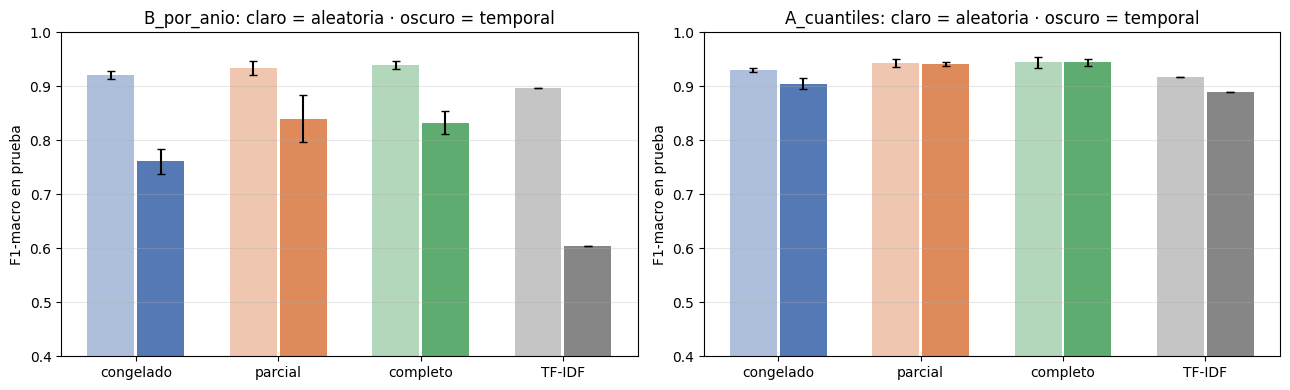

In [18]:
colores = {"congelado": "#4C72B0", "parcial": "#DD8452", "completo": "#55A868", "tfidf_svm": "gray"}
fig, axes = plt.subplots(1, len(CONFIG["disenos"]), figsize=(6.5 * len(CONFIG["disenos"]), 4), squeeze=False)
for ax, disenio in zip(axes[0], CONFIG["disenos"]):
    for j, regimen in enumerate(list(CONFIG["regimenes"]) + ["tfidf_svm"]):
        for k, tipo in enumerate(["aleatoria", "temporal"]):
            v = corridas[(corridas["diseno"] == disenio) & (corridas["regimen"] == regimen) &
                         (corridas["tipo"] == tipo)]["test_f1_macro"]
            if v.empty:
                continue
            x = j + (k - 0.5) * 0.35
            ax.bar(x, v.mean(), width=0.33, color=colores[regimen], alpha=0.45 if tipo == "aleatoria" else 0.95,
                   yerr=v.std() if len(v) > 1 else 0, capsize=3, label=tipo if j == 0 else None)
    ax.set_xticks(range(len(CONFIG["regimenes"]) + 1), list(CONFIG["regimenes"]) + ["TF-IDF"])
    ax.set_ylim(0.4, 1.0); ax.set_ylabel("F1-macro en prueba")
    ax.set_title(f"{disenio}: claro = aleatoria · oscuro = temporal"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(DIR_BASE, "temporal_vs_aleatoria.png"), dpi=150); plt.show()

## §14 · ¿La caída viene del tiempo o de que cambió la fuente?

Acierto en prueba **por fuente**, para el régimen completo. Como casi todas las fuentes publican una sola
clase, el acierto por fuente es el recall de esa clase dentro de esa fuente. Si la partición temporal cae
solo en las fuentes que casi no aparecían en su entrenamiento, el problema es de procedencia más que de
tiempo.

In [19]:
info = sub.set_index("row_id")[["fuente", COL_LABEL, "fecha"]]
top_fuentes = sub["fuente"].value_counts().head(6).index

filas = []
for c in corridas[(corridas["regimen"] == "completo") & corridas["dir"].notna()].itertuples():
    p = pd.read_csv(os.path.join(c.dir, "pred_test.csv")).join(info, on="row_id")
    p["fuente"] = p["fuente"].where(p["fuente"].isin(top_fuentes), "otras")
    p["acierto"] = p["y_true"] == p["y_pred"]
    for fuente, g in p.groupby("fuente"):
        filas.append({"diseno": c.diseno, "tipo": c.tipo, "seed": c.seed, "fuente": fuente,
                      "n": len(g), "acierto": g["acierto"].mean(), "% reales": g["y_true"].mean()})
por_fuente = (pd.DataFrame(filas).groupby(["diseno", "fuente", "tipo"])
                .agg(n=("n", "mean"), acierto=("acierto", "mean"), pct_reales=("% reales", "mean"))
                .unstack("tipo"))
por_fuente.to_csv(os.path.join(DIR_BASE, "acierto_por_fuente.csv"))
print(por_fuente.round(3).to_string())

# ¿Cuántas noticias de cada fuente vio el entrenamiento temporal?
print("\nNoticias de cada fuente en el ENTRENAMIENTO de cada partición:")
vis = {}
for nombre in PARTICIONES:
    f = sub.loc[indices(nombre, "train"), "fuente"]
    vis[nombre] = f.where(f.isin(top_fuentes), "otras").value_counts()
print(pd.DataFrame(vis).fillna(0).astype(int).to_string())

                                               n            acierto          pct_reales         
tipo                                   aleatoria temporal aleatoria temporal  aleatoria temporal
diseno      fuente                                                                              
A_cuantiles actualidadpanamericana.com      19.0      NaN     0.912      NaN      0.000      NaN
            colombiacheck.com              114.0     53.0     0.898    0.862      0.000    0.000
            elchiguirebipolar.net            3.0      3.0     0.667    1.000      0.000    0.000
            elespectador.com               208.0    314.0     0.981    0.985      1.000    1.000
            eltiempo.com                    14.0      NaN     0.952      NaN      1.000      NaN
            lasillavacia.com                18.0     18.0     0.981    1.000      0.000    0.000
            otras                           30.0     17.0     0.933    0.882      0.800    0.647
B_por_anio  actualidadpanameri

In [20]:
# Diseño A: acierto por mes dentro de la prueba temporal (¿empeora a medida que se aleja del corte?)
filas = []
for c in corridas[(corridas["regimen"] == "completo") & (corridas["tipo"] == "temporal") &
                  (corridas["diseno"] == "A_cuantiles")].itertuples():
    p = pd.read_csv(os.path.join(c.dir, "pred_test.csv")).join(info, on="row_id")
    p["mes"] = p["fecha"].dt.to_period("M").astype(str)
    g = p.assign(acierto=p["y_true"] == p["y_pred"]).groupby("mes")
    filas.append(g["acierto"].mean().rename(f"acierto semilla {c.seed}"))
    n_mes = g.size().rename("noticias")
if filas:
    por_mes = pd.concat(filas + [n_mes], axis=1)
    por_mes.to_csv(os.path.join(DIR_BASE, "acierto_por_mes_A.csv"))
    print("Acierto por mes en la prueba temporal del diseño A (régimen completo; columnas = semillas):")
    print(por_mes.round(3).to_string())

Acierto por mes en la prueba temporal del diseño A (régimen completo; columnas = semillas):
         acierto semilla 2026  acierto semilla 42  acierto semilla 7  noticias
mes                                                                           
2026-06                 0.933               0.933              0.933        15
2026-07                 0.979               0.979              0.974       192
2026-08                 0.904               0.928              0.940        83
2026-09                 0.974               0.983              0.983       115


## §15 · Hechos para el informe

La celda imprime las cifras; la interpretación se escribe a partir de ellas. Guía de lectura:

- **Si la temporal cae poco frente a la aleatoria** (dentro de una desviación), el modelo sobrevive al
  cambio de año en este corpus. Junto con la auditoría (que mostró que ignora las fechas), la lectura es:
  no usa el tiempo y tampoco lo necesita, probablemente porque se apoya en rasgos estables como la fuente.
- **Si cae claramente**, entrenar con el pasado no basta para el futuro. Mirar §14: si la caída se
  concentra en fuentes casi ausentes del entrenamiento temporal, la causa es la procedencia; si se reparte
  en todas, es el tiempo (temas, personajes y mentiras nuevas).
- **Comparar el recall de falsas y el de reales:** con 2026 lleno de noticias reales, un F1 estable puede
  esconder que las falsas nuevas se detectan peor.
- **TF-IDF frente a RoBERTa:** si el clásico cae más que el profundo, el profundo generaliza mejor en el
  tiempo; si caen igual, ambos dependen de lo mismo.

**Limitaciones que hay que declarar:** el subconjunto 2018–2026 deja fuera la sátira antigua; los cortes
temporales cambian a la vez el balance de clases y la mezcla de fuentes; las tasas de aprendizaje se
eligieron con la partición aleatoria de la Fase 2; tres semillas por celda.

In [21]:
lineas = ["PARTICIÓN TEMPORAL — RoBERTa-BNE, corpus colombiano 2018–2026", "=" * 90,
          f"Subconjunto: {len(sub):,} noticias (excluidas {excluidas}: antes de 2018 o fecha errónea)", ""]
for _, f in resumen_part.iterrows():
    lineas.append(f"{f['particion']:<26} {f['split']:<5} n={f['n']:>5} · {f['% reales']:>5.1f} % reales · "
                  f"{f['desde']} a {f['hasta']} · {f['% El Espectador']:>5.1f} % El Espectador")
lineas += ["", tabla.to_string(index=False)]
texto = "\n".join(lineas)
print(texto)
with open(os.path.join(DIR_BASE, "hechos_temporal.txt"), "w") as f:
    f.write(texto)

PARTICIÓN TEMPORAL — RoBERTa-BNE, corpus colombiano 2018–2026
Subconjunto: 2,696 noticias (excluidas 563: antes de 2018 o fecha errónea)

B_por_anio__temporal       train n=  750 ·  37.7 % reales · 2018-01-09 a 2024-12-27 ·  14.0 % El Espectador
B_por_anio__temporal       val   n=  905 ·  65.3 % reales · 2025-01-02 a 2025-12-31 ·  64.0 % El Espectador
B_por_anio__temporal       test  n= 1041 ·  72.9 % reales · 2026-01-01 a 2026-09-19 ·  70.7 % El Espectador
B_por_anio__aleatoria      train n=  750 ·  60.5 % reales · 2018-01-16 a 2026-09-19 ·  51.9 % El Espectador
B_por_anio__aleatoria      val   n=  905 ·  60.6 % reales · 2018-01-15 a 2026-09-19 ·  53.8 % El Espectador
B_por_anio__aleatoria      test  n= 1041 ·  60.6 % reales · 2018-01-09 a 2026-09-19 ·  52.3 % El Espectador
A_cuantiles__temporal      train n= 1887 ·  55.2 % reales · 2018-01-09 a 2026-03-18 ·  44.7 % El Espectador
A_cuantiles__temporal      val   n=  404 ·  66.1 % reales · 2026-03-18 a 2026-06-24 ·  64.9 % El Espectado

## §16 · Empaquetar resultados

Todo queda en tu carpeta de Drive (`Entrega 3/particion_temporal/`). Esta celda arma además un `.zip`
para subirlo al repositorio en `Tercera entrega/resultados/particion_temporal/`.

In [22]:
archivo = shutil.make_archive("particion_temporal_fase3", "zip", DIR_BASE)
print(f"✓ {archivo} ({os.path.getsize(archivo)/1e6:.1f} MB)")
if EN_COLAB:
    from google.colab import files
    files.download(archivo)

✓ /content/particion_temporal_fase3.zip (0.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>